# Volet solaire — dimensionnement et IA de nettoyage des panneaux (Kizuna Regenerate)

1. **Dimensionnement** (calcul physique) : plantes → eau → énergie de pompage → nombre de panneaux, avec la
   production réelle du lieu (PVGIS, Commission européenne) et l'évapotranspiration (Open-Meteo ERA5).
2. **IA 1** — production attendue de panneaux PROPRES, entraînée et testée sur de **vraies données** :
   NREL PVDAQ système 4 (1 kWc, Golden, Colorado), 2010-2013, mesures horaires. Entraînement 2010-2012, test 2013.
3. **IA 2** — cause d'une baisse (poussière / panne / rien), sur les vraies journées NREL auxquelles on ajoute des
   défauts connus (méthode semi-simulée, dite telle quelle).
4. **IA 3** — date à laquelle la perte atteindra 5 %, avec poussière et pluie annoncées.

> **Limites honnêtes** : données NREL d'un climat différent de Gabès (le modèle est recalibré sur l'installation
> de l'agriculteur après un nettoyage) ; défauts ajoutés artificiellement ; dans l'application, la production de
> démonstration est simulée sur la vraie météo du lieu tant qu'un capteur ESP32 n'envoie pas de mesures.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
import django; django.setup()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
OLIVE, EAU, SOLEIL, ROUGE, ORANGE, VERT = "#4A5A2A", "#1F6FA8", "#E8A916", "#B83227", "#B85C0E", "#23774A"

## 1. Dimensionnement : combien de panneaux selon le nombre de plantes ?

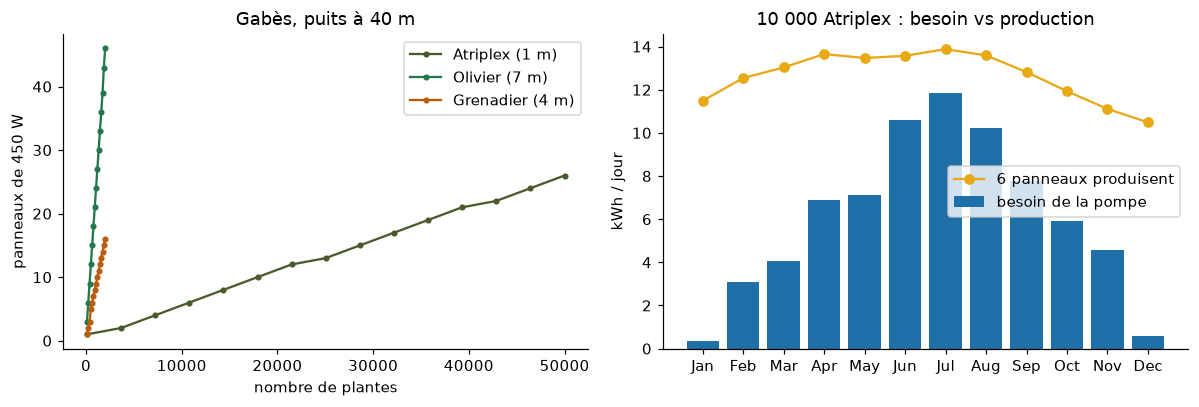

{'nb_panneaux': 6, 'kwc': 2.7, 'pompe_kw': 2.19, 'debit_m3_h': 6.59, 'reservoir_m3': 42.8, 'mois_dimensionnant': 'Jul', 'eau_pointe_m3_jour': 35.63}


In [2]:
from energy.services.climat import GABES
from energy.services.dimensionnement import dimensionner
cultures = {"Atriplex (1 m)": dict(kc=0.65, couverture=0.6, espacement_m=1.0, lr=0.1),
            "Olivier (7 m)": dict(kc=0.70, couverture=0.5, espacement_m=7.0, lr=0.1),
            "Grenadier (4 m)": dict(kc=0.75, couverture=0.5, espacement_m=4.0, lr=0.1)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (nom, p), c in zip(cultures.items(), [OLIVE, VERT, ORANGE]):
    ns = np.linspace(100, 50000 if "Atriplex" in nom else 2000, 15).astype(int)
    pan = [dimensionner([dict(id="Z", culture=nom, nb_plants=int(n), **p)], GABES)["nb_panneaux"] for n in ns]
    ax[0].plot(ns, pan, "-o", ms=3, color=c, label=nom)
ax[0].set(xlabel="nombre de plantes", ylabel="panneaux de 450 W", title="Gabès, puits à 40 m"); ax[0].legend()
d = dimensionner([dict(id="Z", culture="Atriplex", nb_plants=10000, **cultures["Atriplex (1 m)"])], GABES)
m = pd.DataFrame(d["mensuel"])
ax[1].bar(m.mois, m.energie_kwh_jour, color=EAU, label="besoin de la pompe")
ax[1].plot(m.mois, m.production_kwh_jour, "-o", color=SOLEIL, label=f"{d['nb_panneaux']} panneaux produisent")
ax[1].set(ylabel="kWh / jour", title="10 000 Atriplex : besoin vs production"); ax[1].legend()
plt.tight_layout(); plt.show()
print({k: d[k] for k in ("nb_panneaux", "kwc", "pompe_kw", "debit_m3_h", "reservoir_m3", "mois_dimensionnant", "eau_pointe_m3_jour")})

## 2. Les vraies données NREL PVDAQ

31,189 heures brutes → 10,885 heures de jour fiables ; années : {2010: 693, 2011: 3411, 2012: 3645, 2013: 3136}


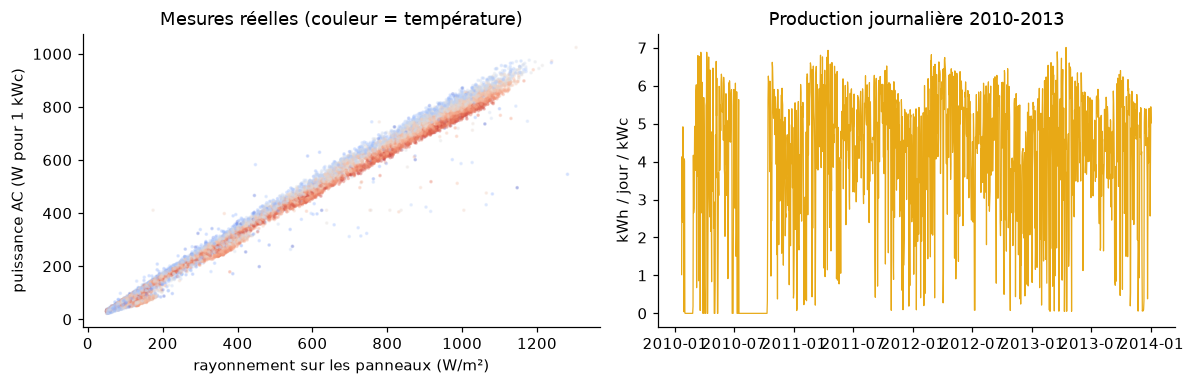

In [3]:
from energy.services.pvdaq import charger
from energy.services.ia_production import nettoyer, entrainer, FEATURES, pvwatts
df = charger(); d = nettoyer(df)
print(f"{len(df):,} heures brutes → {len(d):,} heures de jour fiables ; années : {d.index.year.value_counts().sort_index().to_dict()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(d.poa_w_m2, d.ac_power_w, s=2, alpha=.25, c=d.t_air_c, cmap="coolwarm")
ax[0].set(xlabel="rayonnement sur les panneaux (W/m²)", ylabel="puissance AC (W pour 1 kWc)", title="Mesures réelles (couleur = température)")
jour = df.ac_power_w.clip(lower=0).resample("1D").sum() / 1000
ax[1].plot(jour.index, jour.values, color=SOLEIL, lw=.8)
ax[1].set(ylabel="kWh / jour / kWc", title="Production journalière 2010-2013")
plt.tight_layout(); plt.show()

## 3. IA 1 — production attendue (test sur 2013, année jamais vue)

{
 "donnees": {
  "source": "NREL PVDAQ, système 4 (1 kWc, Golden CO), données réelles horaires",
  "heures_entrainement_2010_2012": 7749,
  "heures_test_2013": 3136
 },
 "modele_ia": {
  "r2": 0.99,
  "mae_w_par_kwc": 12.7,
  "nrmse_pct": 6.4,
  "erreur_energie_jour_pct": 1.1
 },
 "formule_physique_pvwatts": {
  "r2": 0.984,
  "mae_w_par_kwc": 22.2,
  "nrmse_pct": 7.9,
  "erreur_energie_jour_pct": 1.6,
  "rendement_systeme_ajuste": 0.849
 }
}


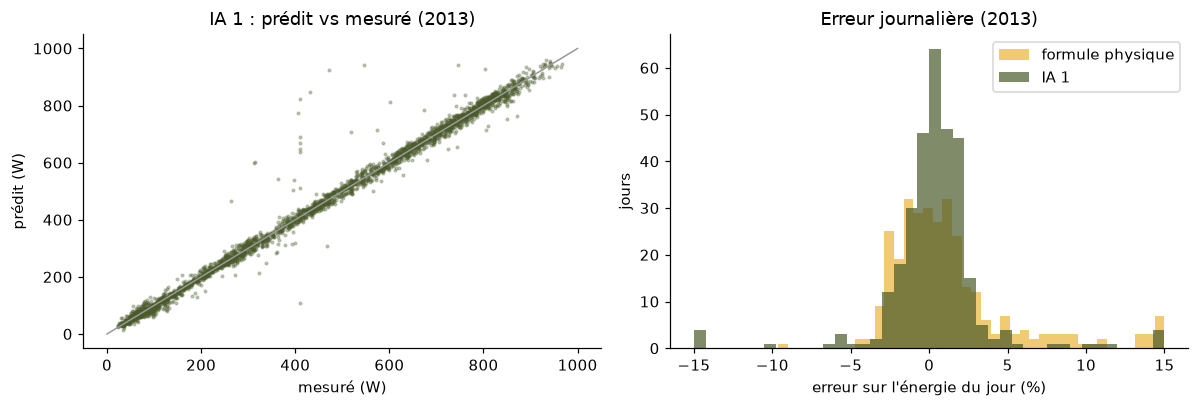

In [4]:
res1 = entrainer(df)
print(json.dumps(res1, indent=1, ensure_ascii=False))
import joblib
from energy.services.ia_production import MODELE
b = joblib.load(MODELE)
test = d[d.index.year == 2013]
p_ia = b["modele"].predict(test[FEATURES])
p_ph = pvwatts(test.poa_w_m2.values, test.t_air_c.values, b["rendement_pvwatts"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(test.ac_power_w, p_ia, s=3, alpha=.3, color=OLIVE, label="IA")
ax[0].plot([0, 1000], [0, 1000], color="#999", lw=1); ax[0].set(xlabel="mesuré (W)", ylabel="prédit (W)", title="IA 1 : prédit vs mesuré (2013)")
e_ia = (pd.Series(p_ia, test.index).resample("1D").sum() / test.ac_power_w.resample("1D").sum() - 1) * 100
e_ph = (pd.Series(p_ph, test.index).resample("1D").sum() / test.ac_power_w.resample("1D").sum() - 1) * 100
ok = test.ac_power_w.resample("1D").sum() > 500
ax[1].hist(e_ph[ok].clip(-15, 15), bins=40, alpha=.6, color=SOLEIL, label="formule physique")
ax[1].hist(e_ia[ok].clip(-15, 15), bins=40, alpha=.7, color=OLIVE, label="IA 1")
ax[1].set(xlabel="erreur sur l'énergie du jour (%)", ylabel="jours", title="Erreur journalière (2013)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. IA 2 — poussière, panne ou rien ?

Indice de performance journalier IP = énergie mesurée ÷ énergie attendue (IA 1 entraînée **sans** l'année en question).
On ajoute à de vraies fenêtres de 21 jours des défauts connus, puis on teste sur 2013.

{
 "exactitude_pct": 97.2,
 "par_classe": {
  "PROPRE": {
   "precision_pct": 99.6,
   "rappel_pct": 97.5
  },
  "POUSSIERE": {
   "precision_pct": 96.7,
   "rappel_pct": 95.9
  },
  "PANNE": {
   "precision_pct": 94.5,
   "rappel_pct": 98.5
  }
 },
 "fausses_alertes_pct": 2.5
}


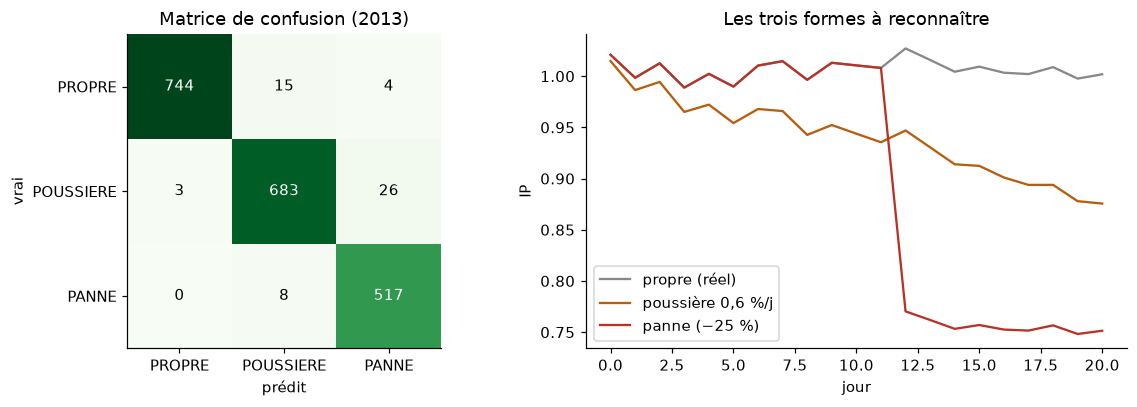

In [5]:
from energy.services import ia_cause
res2 = ia_cause.entrainer(df)
print(json.dumps({k: res2[k] for k in ("exactitude_pct", "par_classe", "fausses_alertes_pct")}, indent=1, ensure_ascii=False))
cm = np.array(res2["matrice_confusion"]["valeurs"]); cl = res2["matrice_confusion"]["lignes_verite_colonnes_prediction"]
ip13 = joblib.load(ia_cause.MODELE)["ip_2013"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(cm, cmap="Greens"); ax[0].set_xticks(range(3), cl); ax[0].set_yticks(range(3), cl)
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set(xlabel="prédit", ylabel="vrai", title="Matrice de confusion (2013)")
v = ip13.values[100:121]
ax[1].plot(v, color="#888", label="propre (réel)")
ax[1].plot(v * (1 - 0.006 * np.arange(1, 22)), color=ORANGE, label="poussière 0,6 %/j")
pan = v.copy(); pan[12:] *= 0.75
ax[1].plot(pan, color=ROUGE, label="panne (−25 %)")
ax[1].set(xlabel="jour", ylabel="IP", title="Les trois formes à reconnaître"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. IA 3 — quand nettoyer ?

In [6]:
from energy.services import ia_prevision
print("Validation (2013) :", ia_prevision.valider(ip13))
ex = ip13.values[40:56] * (1 - 0.006 * np.arange(1, 17))
prev = [{"date": "2026-11-23", "poussiere_max": 20, "pluie_mm": 0}, {"date": "2026-11-24", "poussiere_max": 30, "pluie_mm": 0},
        {"date": "2026-11-25", "poussiere_max": 247, "pluie_mm": 0}]
from datetime import date
print(ia_prevision.recommander(ex, prev, aujourd_hui=date(2026, 11, 22), energie_attendue_kwh_jour=50))

Validation (2013) : {'cas': 199, 'erreur_mediane_jours': 3.0, 'erreur_p80_jours': 7.0, 'biais_moyen_jours': 1.4}
{'perte': 0.0925, 'vitesse_jour': 0.0064, 'jours': 16, 'perte_pct': 9.2, 'vitesse_pct_jour': 0.64, 'jours_avant_seuil': 0, 'seuil_pct': 5, 'action': 'NETTOYER_APRES_TEMPETE', 'date_conseillee': '2026-11-26', 'tempete': {'date': '2026-11-25', 'poussiere_max': 247, 'pluie_mm': 0}, 'pluie': None, 'eau_non_pompee_l_jour': 13886}


## 6. Conclusions

| | Résultat (année de test jamais vue) |
|---|---|
| **IA 1** production attendue | R² 0,99 ; erreur journalière **1,1 %** contre 1,6 % pour la formule physique ; erreur horaire −43 % |
| **IA 2** cause de la baisse | **97 %** de bonnes réponses ; poussière 96 % détectée ; **2,5 %** de fausses alertes |
| **IA 3** date de nettoyage | erreur médiane **3 jours**, 80 % des cas à moins de 7 jours |
| **Dimensionnement** | physique (PVGIS + FAO-56) : le nombre de panneaux suit le nombre de plantes et la profondeur du puits |

**Pourquoi l'IA ici** : détecter 5 % de perte exige une référence plus précise que 5 % ; l'IA 1 est plus précise que la
formule et s'adapte à chaque installation. **Prochaine étape** : brancher un vrai capteur ESP32 (INA226) sur une
installation à Gabès et recaler les modèles sur ses mesures.